# Readmissão hospitalar a 30 dias em doentes com diabetes

**Enterprise Data Science Bootcamp 2026-27 — NOVA IMS**

> _Abstract (a escrever)._

Este notebook é a **carta** do projeto: corre de ponta a ponta,
mas quase não tem lógica própria. Chama o código de `src/` e lê os resultados das bancadas
(`notebooks/01`–`06`) em `reports/` e `docs/figures/`.

**Índice**
- I. Enquadramento do problema
- II. Dados - 2.1 recolha · 2.2–2.3 exploração · 2.4–2.6 preparação
- III. Modelação - 3.1–3.3 baselines e modelos · 3.4–3.5 tuning e seleção · interpretação e fairness
- IV. Deployment

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

FIG = ROOT / "docs" / "figures"
REPORTS = ROOT / "reports"

from src.viz import MODEL_LABELS, bars_page, model_vs_baseline, num, pct, set_style

set_style()
PAGES = REPORTS / "figures"
SOURCE = "Fonte: Diabetes 130-US hospitals (UCI), 1999–2008. "

# I. Enquadramento do problema

_Objetivo, utilizador (equipa de follow-up), métrica de negócio (recall@k)._

# II. Dados

## 2.1 Recolha

Diabetes 130-US hospitals (1999–2008), `data/raw/`. Preparação: `python -m src.data_preparation`.

## 2.2–2.3 Exploração

Detalhe em `notebooks/01_eda.ipynb` e [docs/eda_summary.md](docs/eda_summary.md).

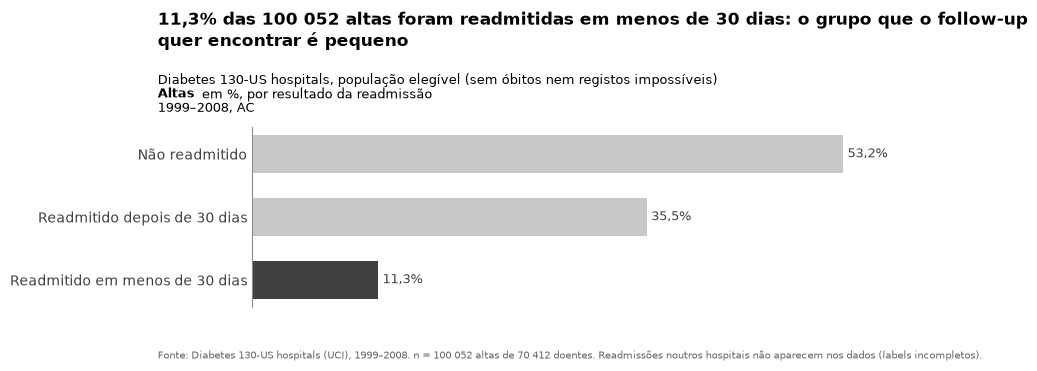

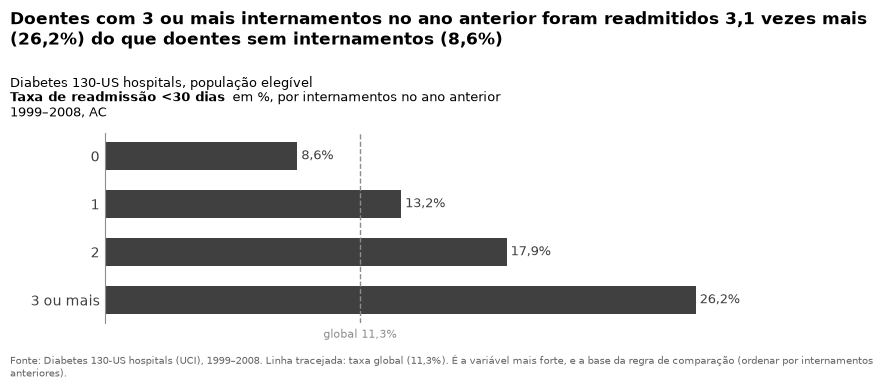

In [2]:
from src.pipeline import read_processed

df = read_processed()
base = df["target"].mean()
dist = df["readmitted"].value_counts(normalize=True).reindex(["NO", ">30", "<30"])
dist.index = ["Não readmitido", "Readmitido depois de 30 dias", "Readmitido em menos de 30 dias"]
bars_page(dist, f"{pct(base)} das {num(len(df))} altas foram readmitidas em menos de 30 dias: "
          "o grupo que o follow-up quer encontrar é pequeno",
          "Diabetes 130-US hospitals, população elegível (sem óbitos nem registos impossíveis)",
          "Altas", "em %, por resultado da readmissão", "1999–2008, AC",
          SOURCE + f"n = {num(len(df))} altas de {num(df['patient_nbr'].nunique())} doentes. "
          "Readmissões noutros hospitais não aparecem nos dados (labels incompletos).",
          highlight=["Readmitido em menos de 30 dias"], figsize=(9, 3.6)).savefig(PAGES / "page_target.png")

inp = df["number_inpatient"].clip(upper=3)
rate = df.groupby(inp)["target"].mean()
rate.index = ["0", "1", "2", "3 ou mais"]
ratio = rate.iloc[-1] / rate.iloc[0]
bars_page(rate, f"Doentes com 3 ou mais internamentos no ano anterior foram readmitidos {num(ratio, 1)} vezes "
          f"mais ({pct(rate.iloc[-1])}) do que doentes sem internamentos ({pct(rate.iloc[0])})",
          "Diabetes 130-US hospitals, população elegível",
          "Taxa de readmissão <30 dias", "em %, por internamentos no ano anterior", "1999–2008, AC",
          SOURCE + f"Linha tracejada: taxa global ({pct(base)}). É a variável mais forte, e a base da regra "
          "de comparação (ordenar por internamentos anteriores).",
          ref=base, ref_label=f"global {pct(base)}", figsize=(9, 3.8)).savefig(PAGES / "page_inpatient.png")

## 2.4–2.6 Preparação

Decisões D1–D16 em [docs/decisions.md](docs/decisions.md); verificação em `notebooks/02_preprocessing_check.ipynb`.

In [3]:
from src.pipeline import load_model_data

data = load_model_data()
print(f"Treino: {len(data.X_train)} encontros · teste: {len(data.X_test)} · {data.X_train.shape[1]} features")

Treino: 80041 encontros · teste: 20011 · 34 features


# III. Modelação

## 3.1–3.3 Baselines e modelos candidatos

Registo de todas as corridas (`notebooks/03`, `04`).

In [4]:
log = pd.read_csv(REPORTS / "experiments.csv")
val = log[(log["dataset"] == "validation") & log["model"].isin(MODEL_LABELS)].drop_duplicates("model", keep="last")
table = (val.assign(Modelo=val["model"].map(MODEL_LABELS)).set_index("Modelo")
         [["pr_auc", "pr_auc_std", "roc_auc", "recall_at_10", "recall_at_20", "brier"]]
         .sort_values("pr_auc", ascending=False))
table.columns = ["PR-AUC", "desvio", "ROC-AUC", "Recall@10%", "Recall@20%", "Brier"]
table.round(3)

,PR-AUC,desvio,ROC-AUC,Recall@10%,Recall@20%,Brier
Modelo,,,,,,
Modelo v1 (HistGradientBoosting),0.234,0.008,0.677,0.247,0.400,0.095
Random forest,0.221,0.004,0.672,0.234,0.386,0.096
Regressão logística L1,0.211,0.008,0.665,0.230,0.386,0.096
Regressão logística,0.210,0.008,0.664,0.229,0.385,0.096
Regressão logística com pesos,0.208,0.008,0.665,0.226,0.383,0.226
Ordenar por internamentos anteriores,0.176,0.004,0.607,0.209,0.341,0.104
Regra: ≥ 1 internamento anterior,0.141,0.002,0.592,0.146,0.297,0.334
Ordem ao acaso,0.113,0.000,0.500,0.096,0.194,0.100


## 3.4–3.5 Tuning, seleção e threshold

_Modelo escolhido, threshold pela capacidade de follow-up e avaliação final no teste (`notebooks/04`)._

Desequilíbrio: pesar as classes não mudou a ordenação (regressão logística `balanced`: PR-AUC 0,208 contra 0,210); por isso não se usou reamostragem e o desequilíbrio trata-se nas métricas e no corte pela capacidade.

A tabela de modelos mede a ordenação em todas as altas (escolha do modelo). A lista de follow-up só tem as **altas elegíveis** (D21): saem as altas para outro hospital ou instituição, internamento, apoio domiciliário ou cuidados paliativos, que já têm acompanhamento. Os cortes por capacidade, a curva de ganhos e a comparação à mesma capacidade são calculados nessas altas.

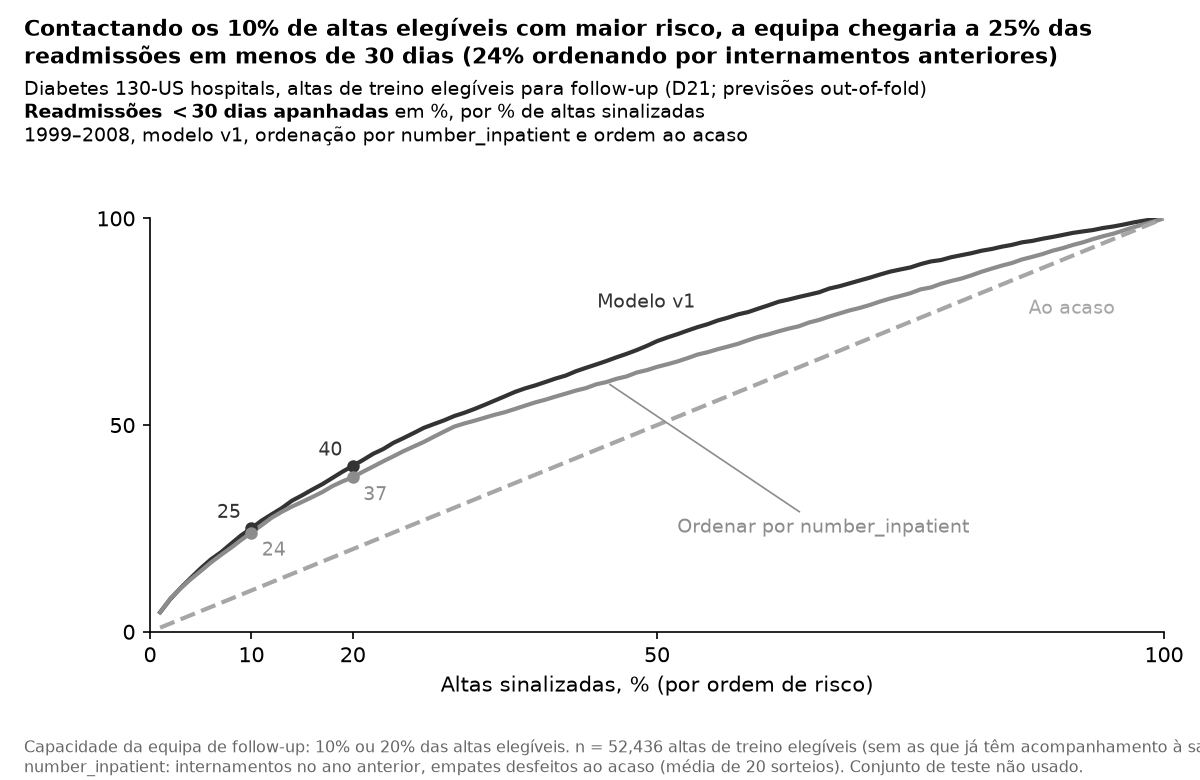

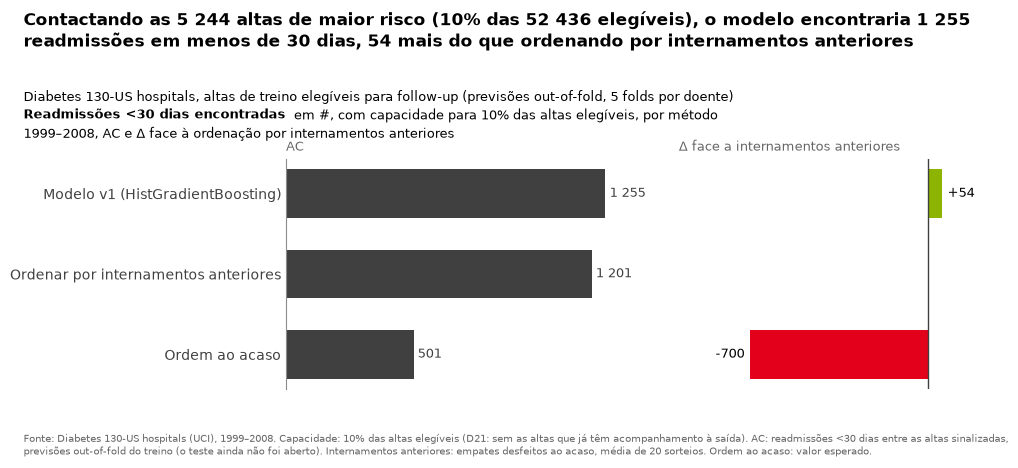

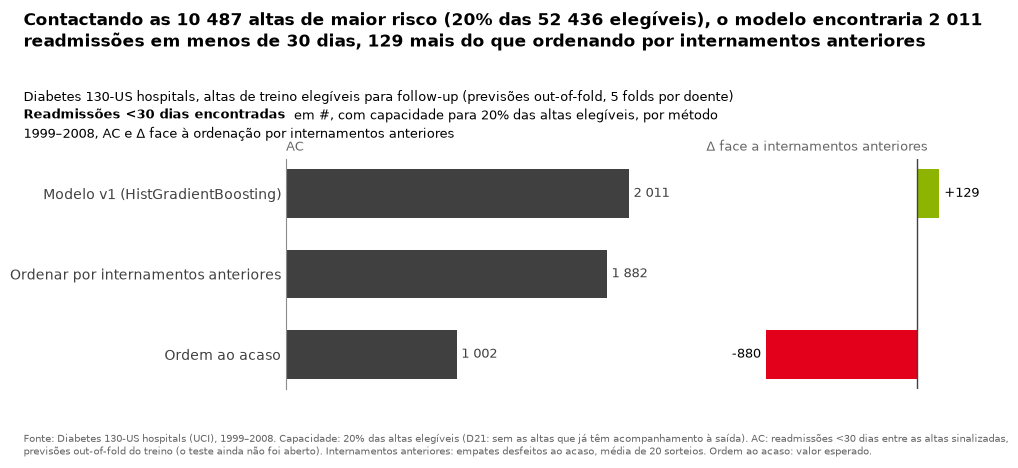

In [5]:
display(Image(PAGES / "gains_curve_v1.png"))  # gerada no notebooks/04

comp = pd.read_csv(REPORTS / "capacity_comparison_v1.csv")  # gerada no notebooks/04
from src.data.population import follow_up_eligible
n_elig = int(follow_up_eligible(data.X_train).sum())  # D21
for k in (0.10, 0.20):
    t = comp[comp["k"] == k].set_index("metodo")
    model_vs_baseline(t, k, n_altas=n_elig,
                      footnote=SOURCE + f"Capacidade: {pct(k, 0)} das altas elegíveis (D21: sem as altas que já têm acompanhamento à saída). AC: readmissões <30 dias entre as altas "
                      "sinalizadas, previsões out-of-fold do treino (o teste ainda não foi aberto). Internamentos "
                      "anteriores: empates desfeitos ao acaso, média de 20 sorteios. Ordem ao acaso: valor esperado."
                      ).savefig(PAGES / f"page_model_vs_baseline_k{int(k * 100)}.png")

**Qual o risco (D22).** O score do modelo é apresentado como risco estimado de readmissão em menos de 30 dias.
Nas previsões out-of-fold, o risco previsto bate certo com as readmissões observadas em cada decil:

In [6]:
calib = pd.read_csv(REPORTS / "calibration_v1.csv")  # gerada no notebooks/04
t = calib[calib["altas"] == "elegiveis"].set_index("grupo")[["n", "risco_previsto", "observado"]]
t.columns = ["Altas", "Risco previsto", "Readmissões observadas"]
t.style.format({"Altas": lambda v: num(v), "Risco previsto": lambda v: pct(v), "Readmissões observadas": lambda v: pct(v)})

,Altas,Risco previsto,Readmissões observadas
grupo,,,
1,5 244,"3,3%","3,8%"
2,5 244,"4,7%","4,7%"
3,5 243,"5,6%","5,8%"
4,5 244,"6,4%","6,5%"
5,5 243,"7,3%","7,5%"
6,5 244,"8,3%","8,6%"
7,5 243,"9,5%","8,7%"
8,5 244,"11,3%","11,5%"
9,5 243,"14,4%","14,4%"


## Interpretação e fairness

_Importância por permutação e métricas por idade/raça/sexo (`notebooks/05`)._

# IV. Deployment

_Modelo em `models/v1/` (`model.skops` + `config.json` + model card); app Gradio em `src/app.py` (`python -m src.app`)._

# Conclusões e limitações

_Ex.: os `>30` contam como negativos (D6); teto de desempenho do dataset (ROC-AUC ≈ 0,65–0,70)._